# Ideas

1. **Image Preprocessing**
    -   **Dataset Augmentation**
        *   x10 the training dataset
    -   Grayscaling
        *   Primarily reduce the computational power
2. **Intuitively Group Age Classes**
    -   Roblox: 5-8, 9-12, 13-15, 16-17, 18-20, and 21+
    -   Business-wise, we have to add more label for 21+
    -   Suggestion for 21+ group: 21-27, 28-45, 46-65, 66+
        -   21-27 years: Categorized as mature adults.
        -   28-45 years: Representing the adult stage of life.
        -   46-65 years: Distinguished by the appearance of more pronounced aging features.
        -   66+ years: Represented by features like graying hair and aging skin.
3. Use CNN-Based Deep Learning Aproach


Concluded labels: 1-4, 5-8, 9-12, 13-15, 16-17, 18-20, 21-27, 28-45, 46-65, 66+

# Import Libraries and Setup Environments

In [1]:
# Standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from keras import mixed_precision, layers, models
from keras.models import Sequential, Model
from keras.layers import Conv2D, MaxPooling2D, AveragePooling2D, GlobalAveragePooling2D, Flatten, Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img # From old Keras' API. For data augmentation, Keras has imported a new API in TensorFlow 2.x. So, we can use it directly from TensorFlow.
from keras.utils import to_categorical, plot_model
from keras.optimizers import SGD, Adam
from keras.callbacks import ReduceLROnPlateau, EarlyStopping
from keras.applications import VGG16, MobileNetV2
from keras.applications.vgg16 import preprocess_input as vgg_preprocess
from keras.applications.mobilenet_v2 import preprocess_input as mobile_preprocess

# Others:
from pathlib import Path
import os
import cv2
from tqdm.notebook import tqdm
import imagehash 
from PIL import Image

I0000 00:00:1792224398.603762   15064 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792224398.873643   15064 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792224400.570345   15064 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("GPU devices:", gpus)

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# This will reduce the VRAM consumed
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
    print("GPU Memory Growth Enabled!")

GPU Memory Growth Enabled!


In [4]:
# For strong GPUs, execute this code cell to turn on FP16 and reduce VRAM usage consumed
mixed_precision.set_global_policy("mixed_float16")

# Load the Dataset

In [5]:
import kagglehub

# Find the root folder of the project
PROJECT_ROOT = Path.cwd()

# This is for notebooks that is opened in notebooks/ (folder)
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# The function to download dataset immediately into data/raw
def download_dataset(kaggle_url: str, folder_name: str) -> Path:
    """Download a Kaggle dataset into its own directory.
    - kaggle_url: author/dataset-name (on Kaggle)
    - folder_name: the name of the folder that will hold the dataset"""
    output_dir = DATA_DIR / folder_name
    output_dir.mkdir(parents=True, exist_ok=True)

    path = kagglehub.dataset_download(
        kaggle_url,
        output_dir=str(output_dir),
        force_download=True
    )

    print(f"Dataset: {kaggle_url}")
    print(f"Saved to: {path}")
    print()

    return Path(path)

In [6]:
#utk_path = download_dataset("jangedoo/utkface-new", "utkface")
#facial_age_v1_path = download_dataset("frabbisw/facial-age","facial-age-v1")

In [7]:
utk_path = '/home/sisi/projects/age-estimation/data/raw/utkface'
BASE_DIR = os.path.join(utk_path, "UTKFace")
print(BASE_DIR)

/home/sisi/projects/age-estimation/data/raw/utkface/UTKFace


In [8]:
image_paths = []
age_labels = []

for filename in tqdm(os.listdir(BASE_DIR)):
    image_path = os.path.join(BASE_DIR, filename)
    components = filename.split("_")
    age = int(components[0])
    image_paths.append(image_path)
    age_labels.append(age)

  0%|          | 0/23708 [00:00<?, ?it/s]

In [9]:
df = pd.DataFrame()
df['image'], df['age'] = image_paths, age_labels
df.head()

,image,age
0,/home/sisi/projects/age-estimation/data/raw/ut...,39
1,/home/sisi/projects/age-estimation/data/raw/ut...,23
2,/home/sisi/projects/age-estimation/data/raw/ut...,26
3,/home/sisi/projects/age-estimation/data/raw/ut...,31
4,/home/sisi/projects/age-estimation/data/raw/ut...,42


# EDA

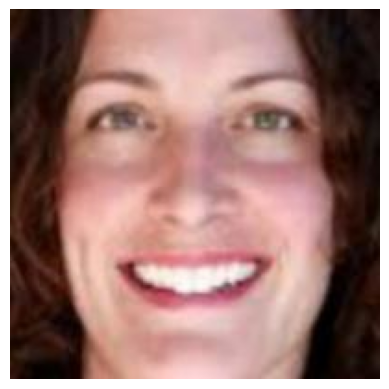

In [10]:
img = Image.open(df['image'][0])
plt.axis('off')
plt.imshow(img) # Semi-colon prevents the console to show anything else but the image

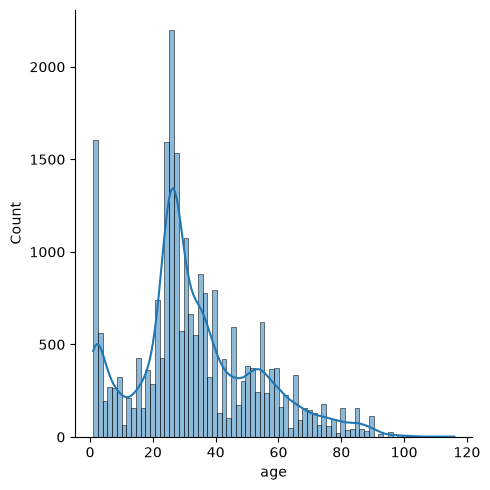

In [ ]:
sns.displot(df['age'], kde=True)

One-hot encoded targets shape: (23708, 8)


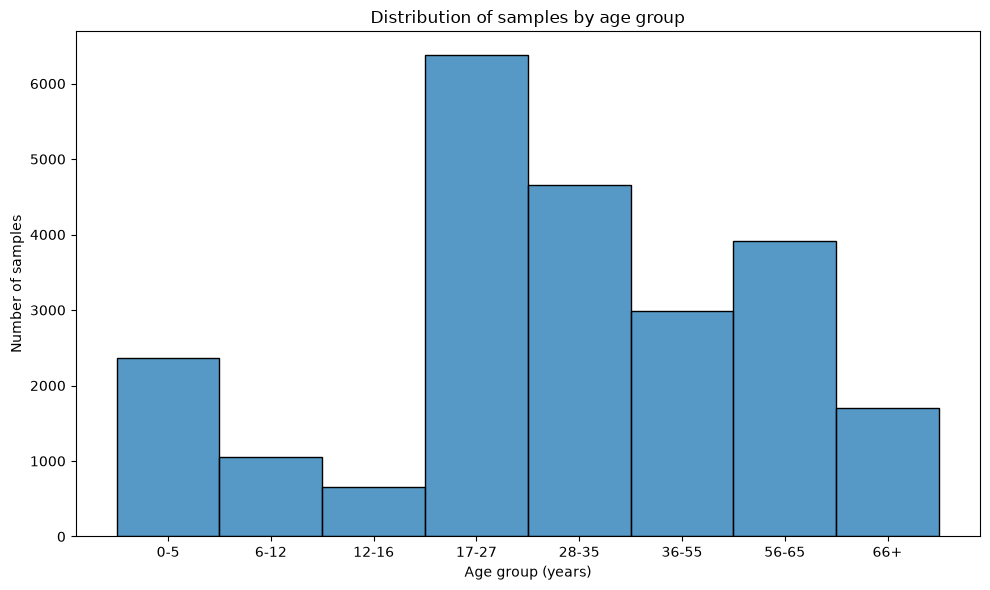

In [12]:
def map_age_to_group(age):
    if age <= 5: # 0-5
        return 0
    elif age <= 12: # 6-12
        return 1
    elif age <= 16: # 12-16
        return 2
    elif age <= 27: # 17-27
        return 3
    elif age <= 35: # 28-35
        return 4
    elif age <= 45: # 36-55
        return 5
    elif age <= 65: # 56-65
        return 6
    else:           # 66+
        return 7

# Map each age to its group index (0-9)
df['age_group'] = df['age'].apply(map_age_to_group)

# Convert indices to one-hot encoded representation
y_age_cat = to_categorical(df['age_group'], num_classes=8)
print("One-hot encoded targets shape:", y_age_cat.shape)

age_group_labels = ["0-5", "6-12", "12-16", "17-27", "28-35", "36-55", "56-65", "66+"]
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="age_group", discrete=True)
plt.xticks(range(len(age_group_labels)), age_group_labels)
plt.xlabel("Age group (years)")
plt.ylabel("Number of samples")
plt.title("Distribution of samples by age group")
plt.tight_layout()

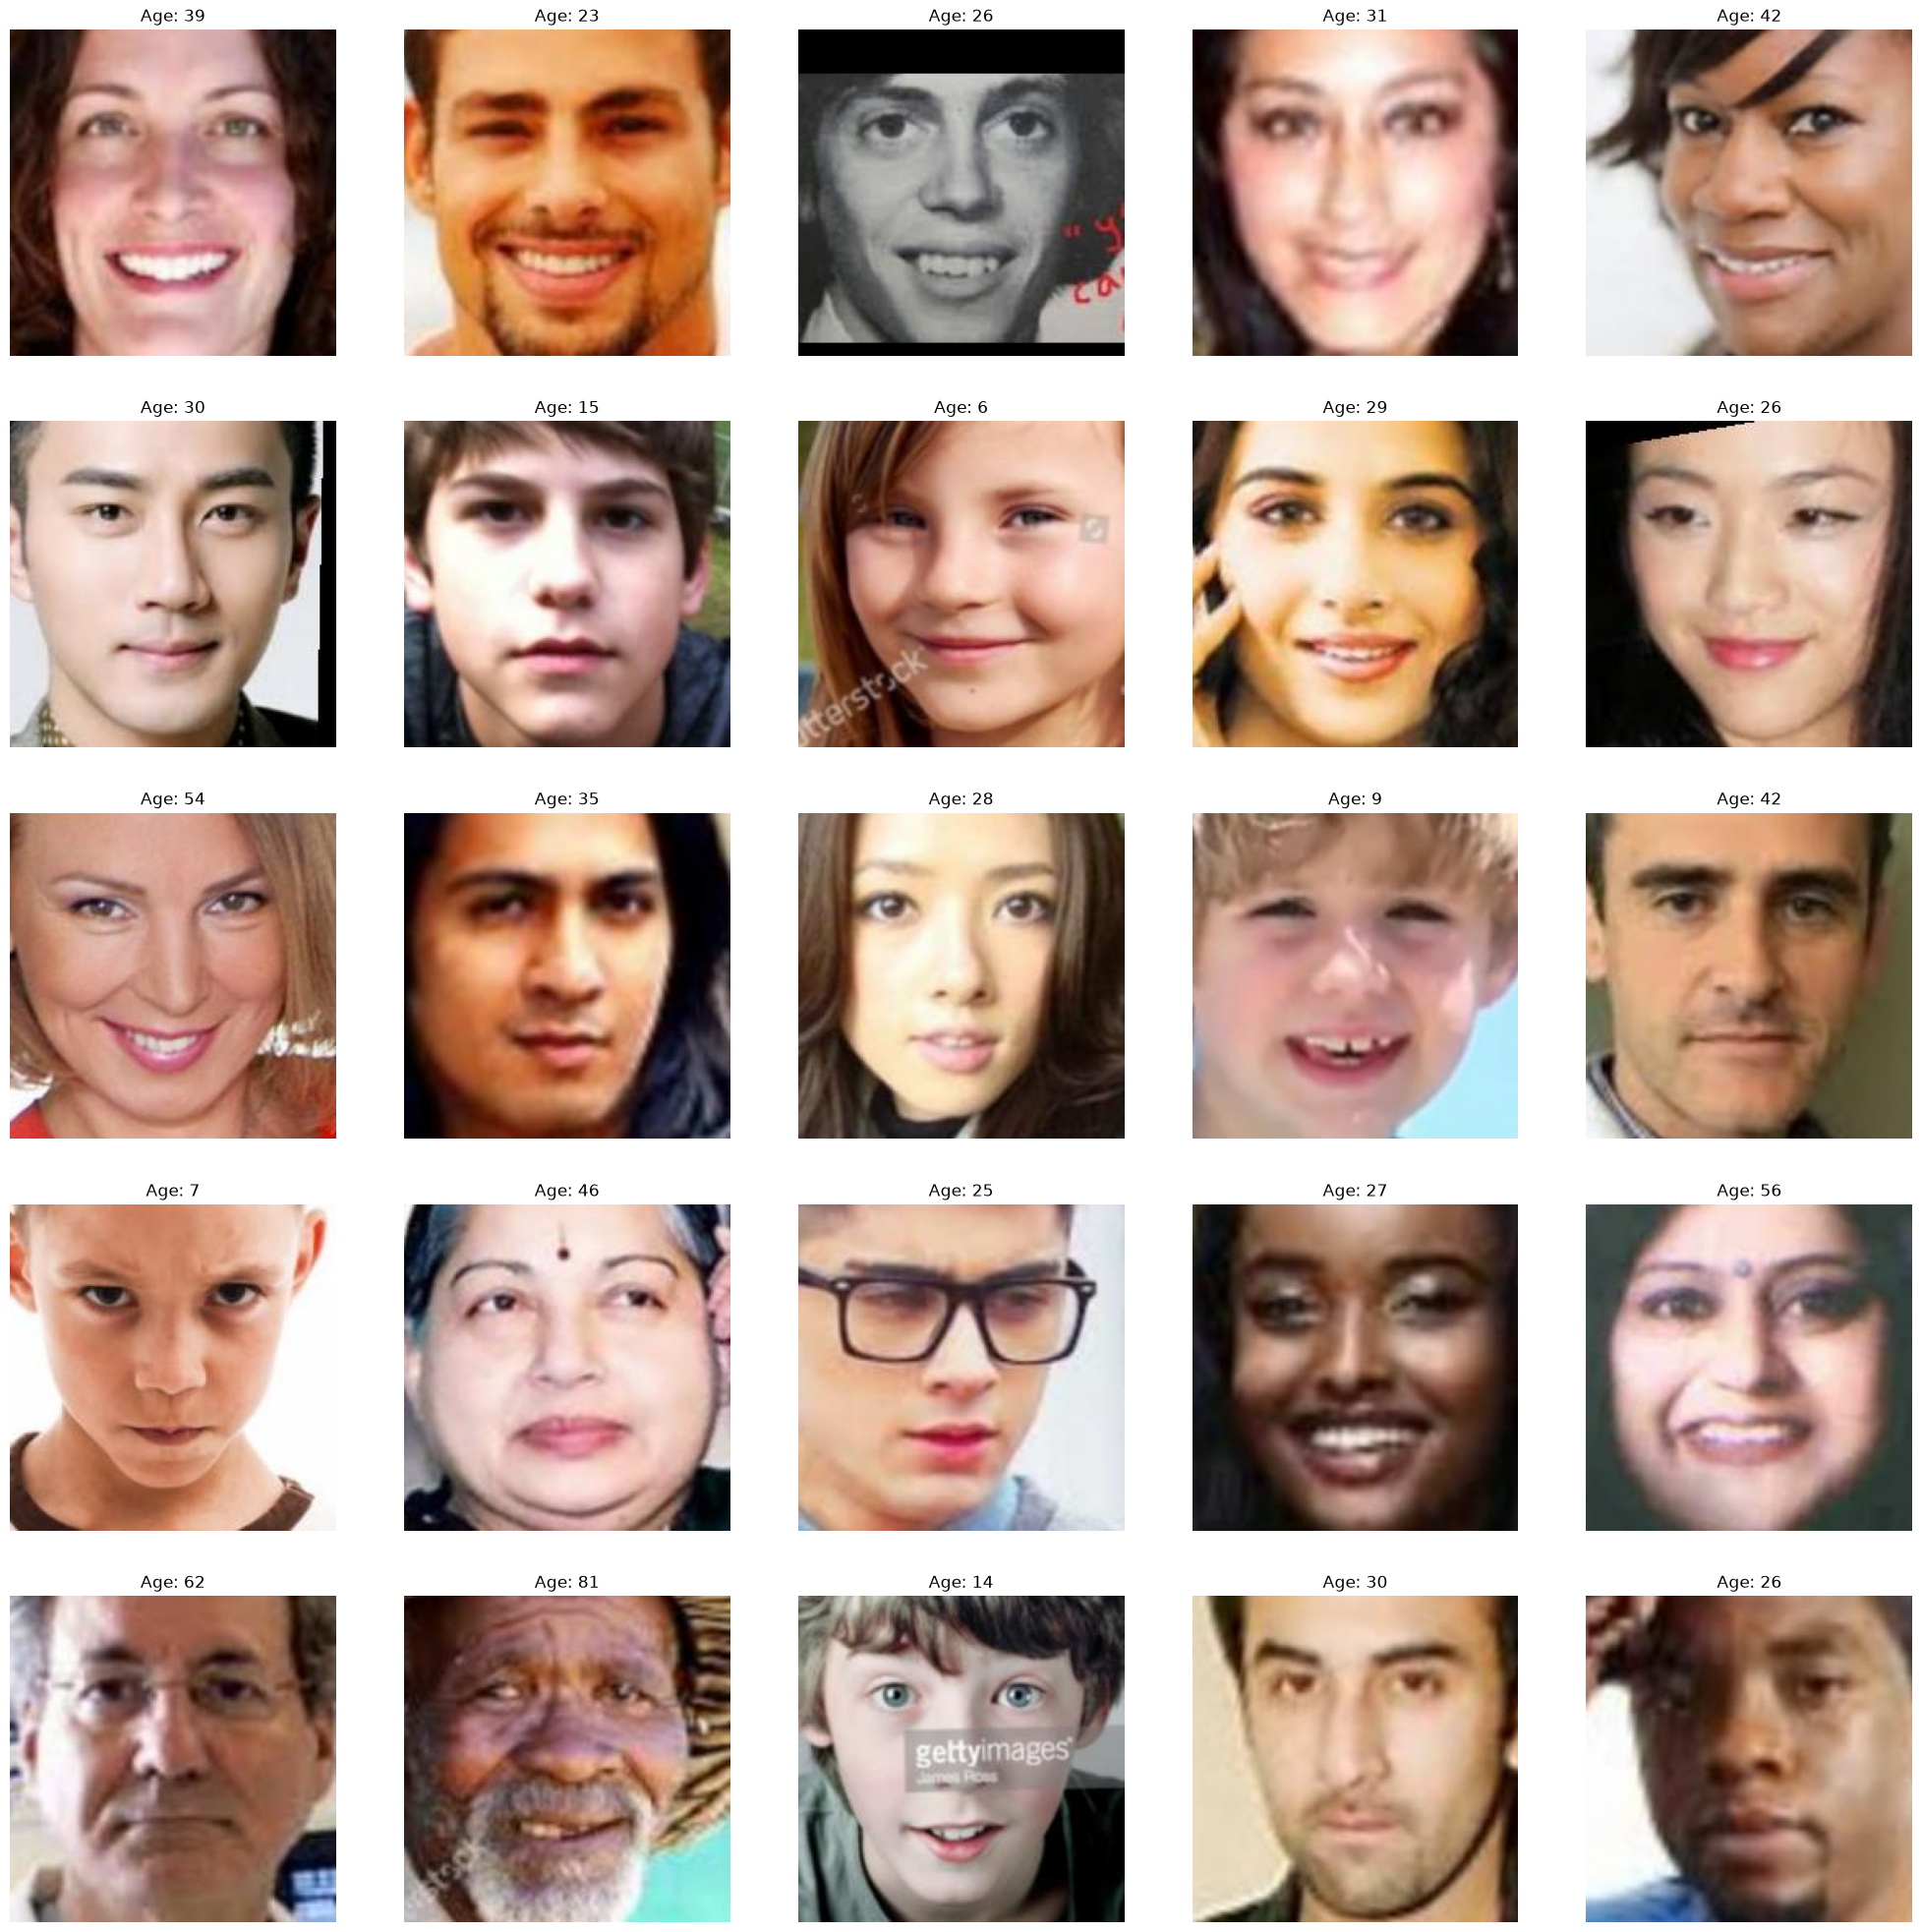

In [13]:
plt.figure(figsize=(25, 25))
files = df.iloc[0:25]
for index, file, age, age_group in files.itertuples():
    plt.subplot(5, 5, index+1)
    img = load_img(file)
    img = np.array(img)
    plt.imshow(img)
    plt.title(f"Age: {age}")
    plt.axis('off')

# Feature Extraction

In [14]:
def extract_features(images, size:int):
    features = []
    for image in tqdm(images):
        img = load_img(image, color_mode="grayscale")

        # Use Image.Resampling.LANCZOS instead of deprecated Image.ANTIALIAS
        resample_filter = Image.Resampling.LANCZOS if hasattr(Image, 'Resampling') else Image.ANTIALIAS
        img = img.resize((size, size), resample_filter)

        img = np.array(img)
        features.append(img)

    features = np.array(features)
    features = features.reshape(len(features), size, size, 1)

    return features

In [15]:
X = extract_features(df['image'], size=200)

  0%|          | 0/23708 [00:00<?, ?it/s]

In [16]:
X.shape

(23708, 200, 200, 1)

In [17]:
# Normalization
X = X.astype('float32') / 255.0

y_age = np.array(df['age'])

In [18]:
X_train, X_holdout, y_train, y_holdout, groups_train, groups_holdout, ages_train, ages_holdout = train_test_split(
    X,
    y_age_cat,
    df["age_group"].to_numpy(),
    y_age,
    test_size=0.2,
    stratify=df["age_group"],
    random_state=42,
)

X_val, X_test, y_val, y_test, ages_val, ages_test = train_test_split(
    X_holdout,
    y_holdout,
    ages_holdout,
    test_size=0.5,
    stratify=groups_holdout,
    random_state=42,
)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Train: 18966 | Validation: 2371 | Test: 2371


In [19]:
simple_model = Sequential()

simple_model.add(Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(200, 200, 1)))
simple_model.add(BatchNormalization())
simple_model.add(MaxPooling2D(pool_size=(2, 2), strides=2))

simple_model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
simple_model.add(BatchNormalization())
simple_model.add(MaxPooling2D(pool_size=(2, 2), strides=2))

simple_model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
simple_model.add(BatchNormalization())
simple_model.add(MaxPooling2D(pool_size=(2, 2), strides=2))

simple_model.add(Conv2D(256, (3, 3), padding='same', activation='relu'))
simple_model.add(BatchNormalization())
simple_model.add(MaxPooling2D(pool_size=(2, 2), strides=2))

simple_model.add(GlobalAveragePooling2D())
simple_model.add(Dense(128, activation='relu'))
simple_model.add(Dropout(.3))
simple_model.add(Dense(32, activation='relu'))
simple_model.add(Dropout(.3))
simple_model.add(Dense(8, activation='softmax'))

/home/sisi/projects/age-estimation/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1792224418.394181   15064 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13549 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Ti SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9


In [20]:
simple_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 200, 200, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100, 100, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 50, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 25, 25, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 25, 25, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 427,048 (1.63 MB)

 Trainable params: 426,088 (1.63 MB)

 Non-trainable params: 960 (3.75 KB)

In [21]:
#plot_model(simple_model, dpi=64)

In [22]:
simple_model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)
# Add early stopping to prevent overfitting and save the best model
early_stop = EarlyStopping(
    monitor='val_loss',             # Monitor the validation loss
    patience=10,                    # Number of epochs to wait before stopping
    restore_best_weights=True,      # Restore the weights of the best epoch
    verbose=1                       # Print a message when early stopping is triggered
)


In [23]:
history = simple_model.fit(
    x=X_train,
    y=y_train,
    batch_size=128,
    epochs=100,
    callbacks=[early_stop],
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/100


I0000 00:00:1792224426.799830   15228 service.cc:153] XLA service 0x72f54804d390 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792224426.799862   15228 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 Ti SUPER, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792224426.839455   15228 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792224427.330949   15228 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792224427.442645   15228 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5431__.105
I0000 00:00:1792224429.824438   15228 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set in

147/149 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.2851 - loss: 1.8736

I0000 00:00:1792224449.268025   15228 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5431__.105
I0000 00:00:1792224449.951648   15228 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.2860 - loss: 1.8725

I0000 00:00:1792224460.513230   15225 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792224460.970830   15225 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792224462.170319   15228 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792224463.024976   15228 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the 

149/149 ━━━━━━━━━━━━━━━━━━━━ 40s 151ms/step - accuracy: 0.2860 - loss: 1.8725 - val_accuracy: 0.1653 - val_loss: 2.2618
Epoch 2/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.3650 - loss: 1.6401 - val_accuracy: 0.1084 - val_loss: 2.0687
Epoch 3/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.4077 - loss: 1.5078 - val_accuracy: 0.1708 - val_loss: 2.8181
Epoch 4/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.4441 - loss: 1.3984 - val_accuracy: 0.3631 - val_loss: 1.5973
Epoch 5/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.4745 - loss: 1.3071 - val_accuracy: 0.3349 - val_loss: 1.6356
Epoch 6/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.4916 - loss: 1.2413 - val_accuracy: 0.4618 - val_loss: 1.3456
Epoch 7/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.5104 - loss: 1.1930 - val_accuracy: 0.3893 - val_loss: 1.6824
Epoch 8/100
149/149 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.5321 - loss: 1.1391 - val_accura

# Evaluate the model

In [25]:
score = simple_model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

I0000 00:00:1792224627.447764   15226 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


Test loss: 1.1735243797302246
Test accuracy: 0.5301560759544373


# Predict on Random images

E0000 00:00:1792224630.242144   15064 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Random IDs: [1192, 420, 506, 1406]
Predicted age groups: ['56-65', '56-65', '17-27', '17-27']
Actual age groups: ['56-65', '66+', '17-27', '17-27']


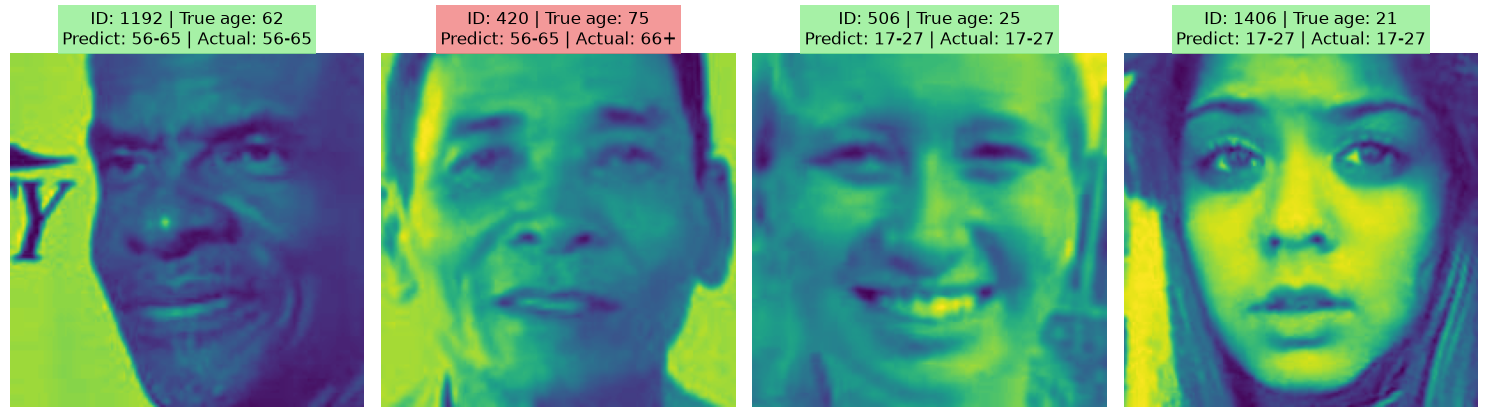

In [26]:
random_ids = np.random.choice(len(X_test), size=4, replace=False)

predictions = simple_model.predict(X_test[random_ids], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test[random_ids], axis=1)

print('Random IDs:', random_ids.tolist())
print('Predicted age groups:', [age_group_labels[label] for label in predicted_labels])
print('Actual age groups:', [age_group_labels[label] for label in actual_labels])

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, image_id, predicted_label, actual_label, true_age in zip(axes.flat, random_ids, predicted_labels, actual_labels, ages_test[random_ids]):
    ax.imshow(X_test[image_id])
    match_color = 'lightgreen' if predicted_label == actual_label else 'lightcoral'
    ax.set_facecolor(match_color)
    title = ax.set_title(
        f'ID: {image_id} | True age: {true_age}\nPredict: {age_group_labels[predicted_label]} | Actual: {age_group_labels[actual_label]}'
    )
    title.set_bbox(dict(facecolor=match_color, alpha=0.8, edgecolor='none', pad=3))
    ax.axis('off')

plt.tight_layout()
plt.show()

# Visualize intermediate outputs of simple_model

In [ ]:
# 1. Select convolutional, pooling, and dense layers
visualization_layers = [
    layer for layer in simple_model.layers
    if isinstance(layer, (
        Conv2D,
        MaxPooling2D,
        GlobalAveragePooling2D,
        Dense
    ))
]

# 2. Create a model that returns all selected layer outputs
visualization_model = tf.keras.Model(
    inputs=simple_model.inputs,
    outputs=[layer.output for layer in visualization_layers]
)


Test image ID: 506


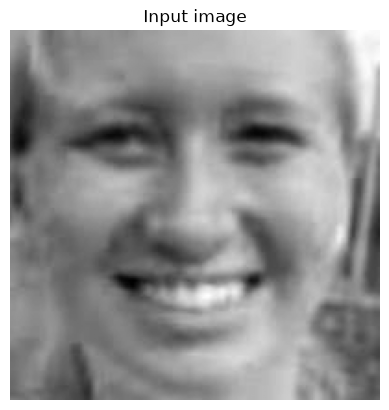

/home/sisi/projects/age-estimation/.venv/lib/python3.13/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 200, 200, 1))
  warnings.warn(msg)


conv2d: (200, 200, 32)


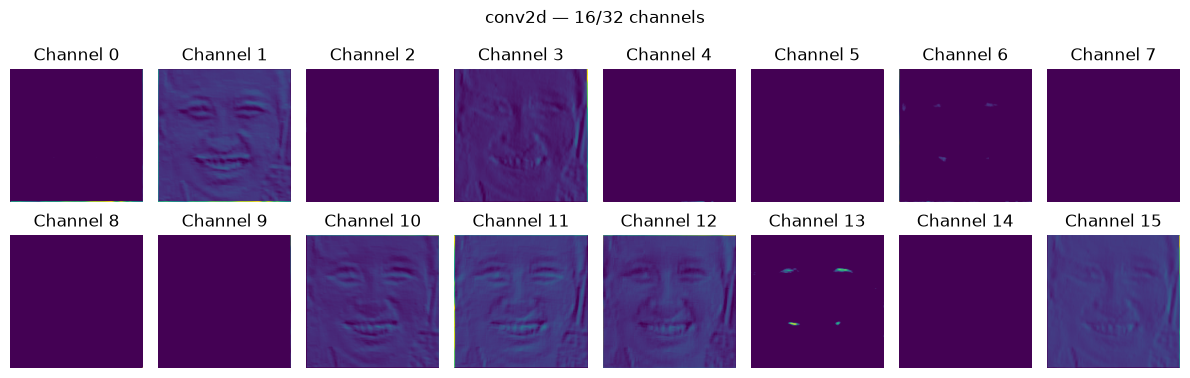

max_pooling2d: (100, 100, 32)


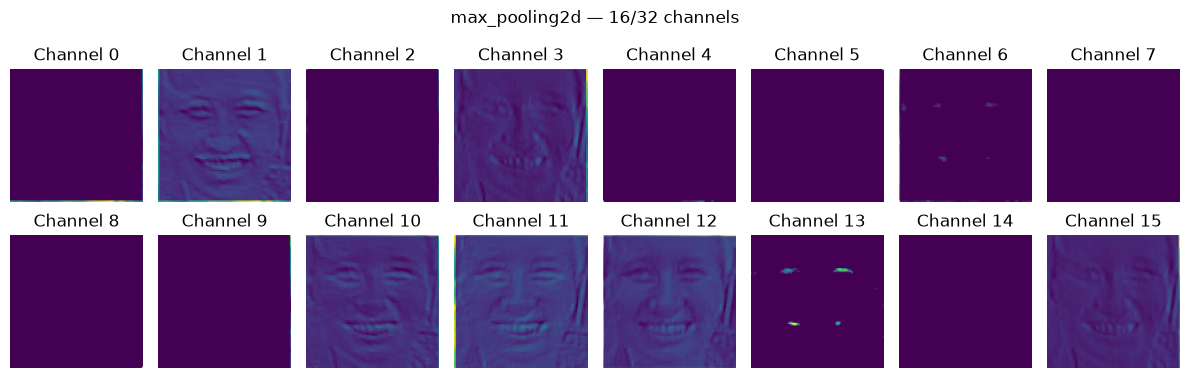

conv2d_1: (100, 100, 64)


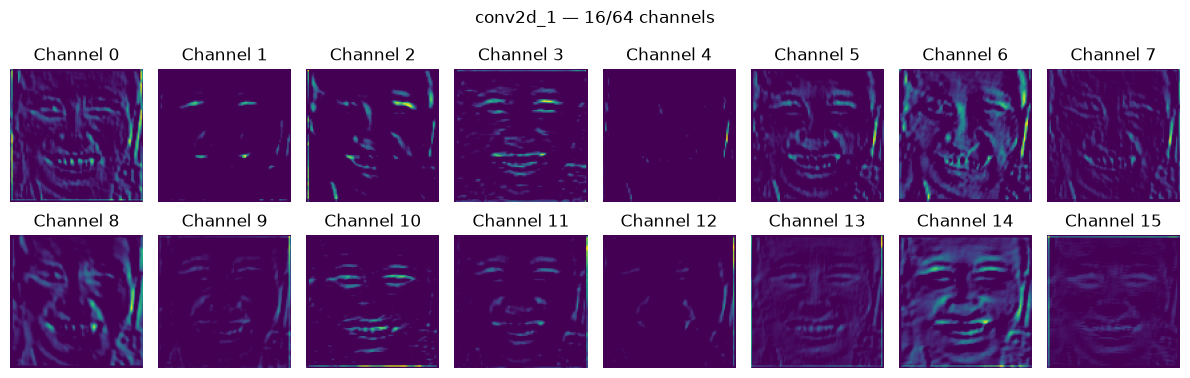

max_pooling2d_1: (50, 50, 64)


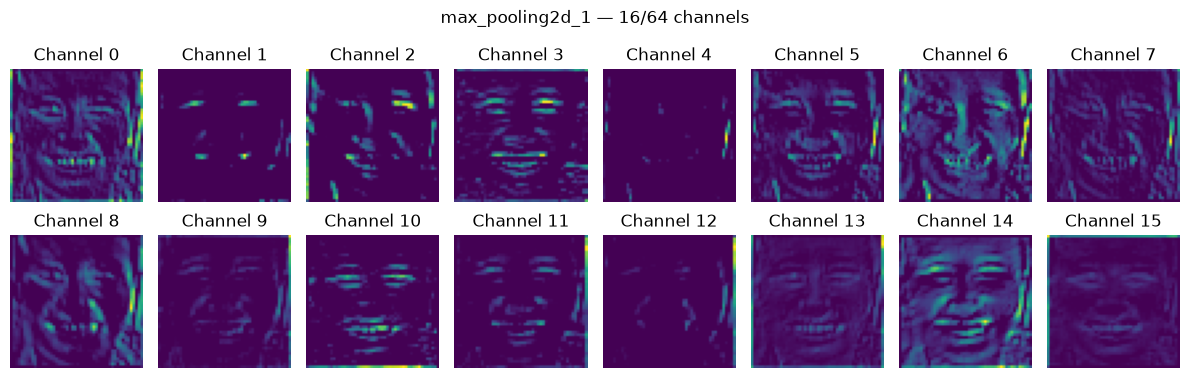

conv2d_2: (50, 50, 128)


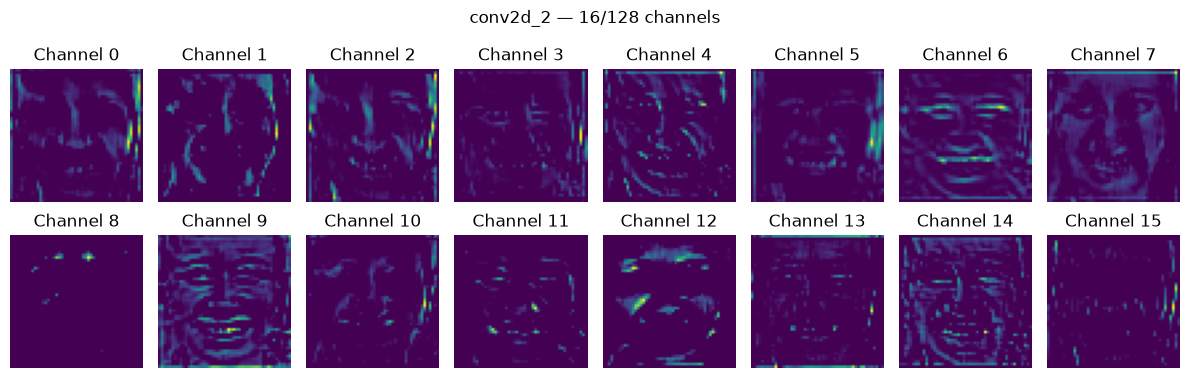

max_pooling2d_2: (25, 25, 128)


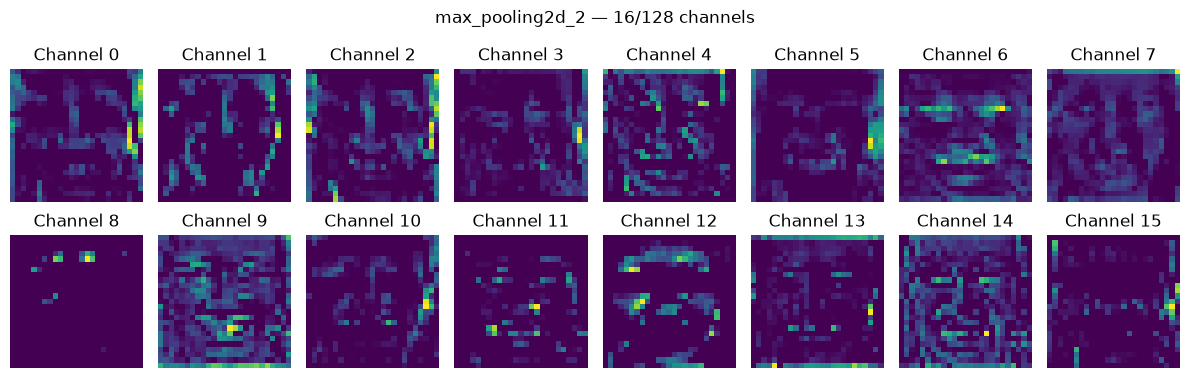

conv2d_3: (25, 25, 256)


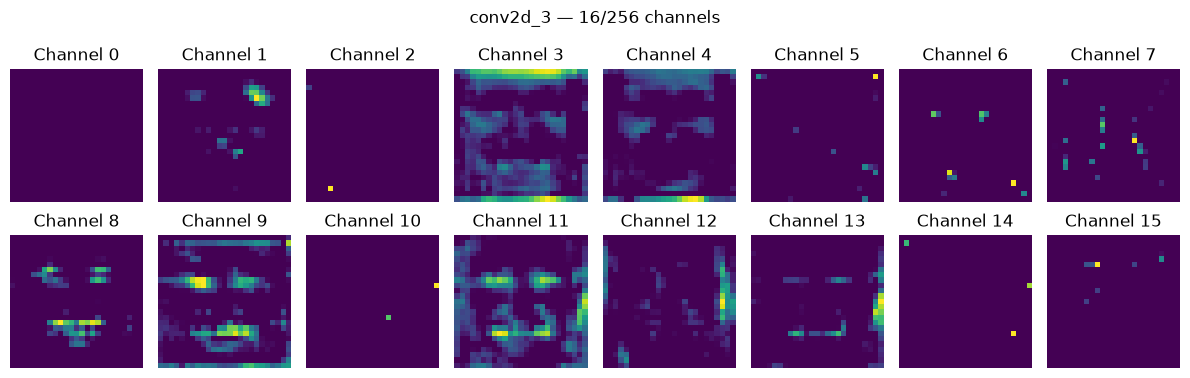

max_pooling2d_3: (12, 12, 256)


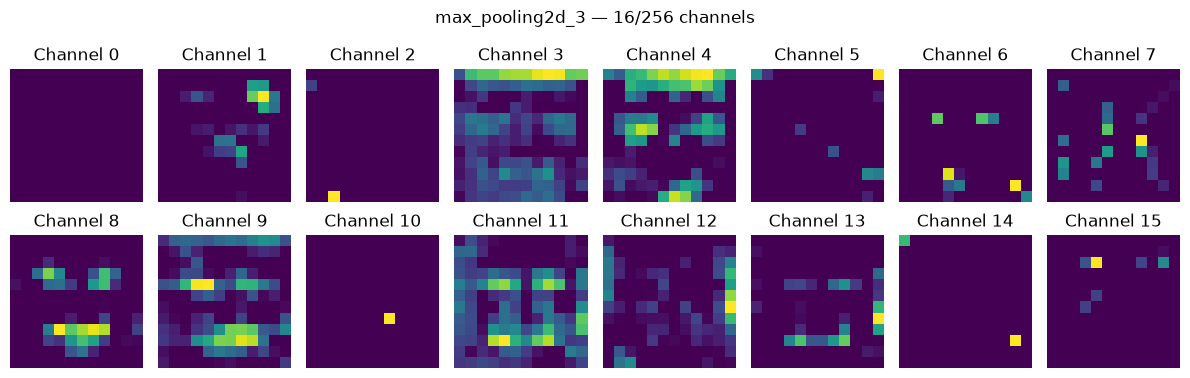

global_average_pooling2d: (256,)


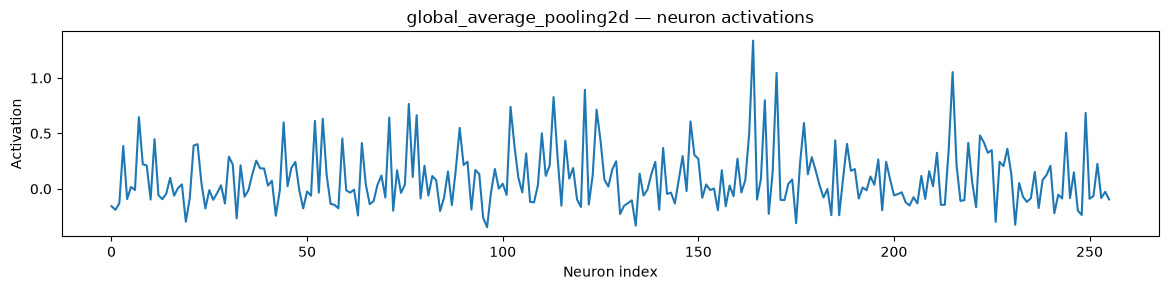

dense: (128,)


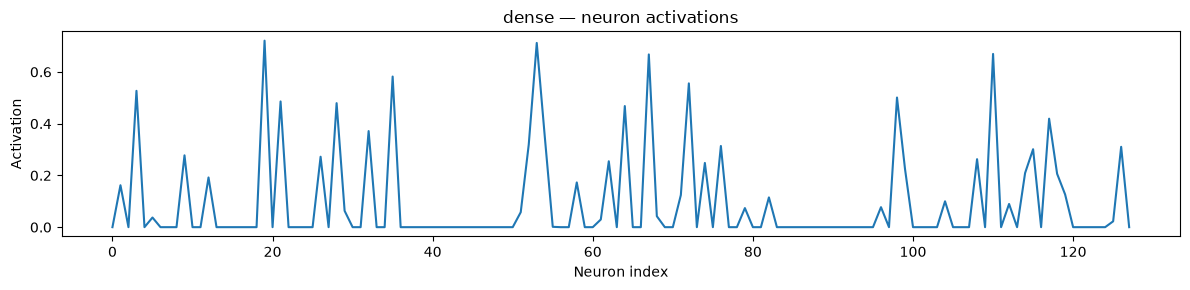

dense_1: (32,)


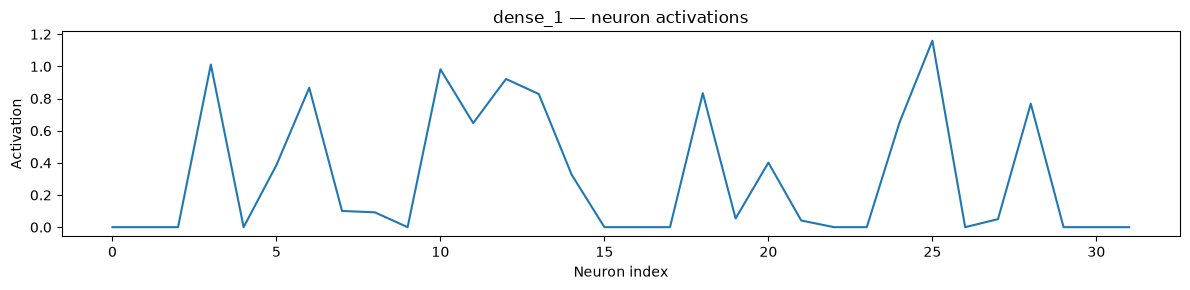

dense_2: (8,)


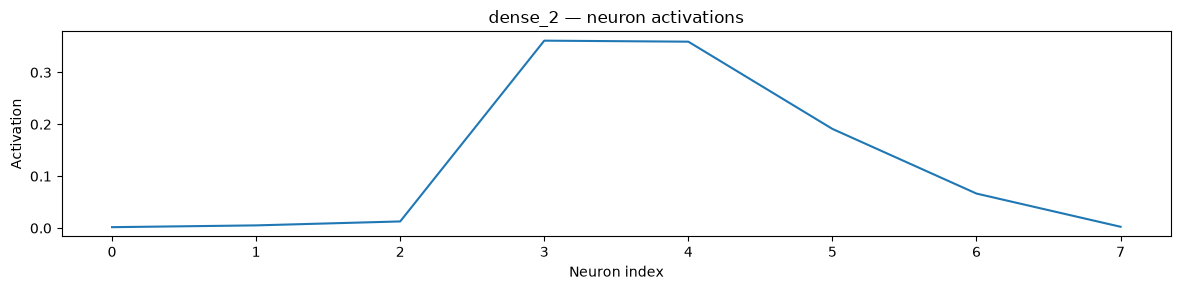

In [ ]:
def visualize_layer_outputs(model, image, max_channels=16):
    image_batch = np.expand_dims(image, axis=0)
    outputs = model(image_batch, training=False)

    for layer, output in zip(visualization_layers, outputs):
        values = output[0].numpy()
        print(f"{layer.name}: {values.shape}")

        if values.ndim == 3:
            n_channels = min(values.shape[-1], max_channels)
            n_cols = 8
            n_rows = int(np.ceil(n_channels / n_cols))
            fig, axes = plt.subplots(
                n_rows, n_cols,
                figsize=(12, 2 * n_rows),
                squeeze=False
            )

            for i, ax in enumerate(axes.flat):
                if i < n_channels:
                    ax.imshow(values[:, :, i], cmap="viridis")
                    ax.set_title(f"Channel {i}")
                ax.axis("off")
            fig.suptitle(
                f"{layer.name} — {n_channels}/{values.shape[-1]} channels"
            )
            plt.tight_layout()
            plt.show()

        elif values.ndim == 1:
            fig, ax = plt.subplots(figsize=(12, 3))
            ax.plot(values)
            ax.set_title(f"{layer.name} — neuron activations")
            ax.set_xlabel("Neuron index")
            ax.set_ylabel("Activation")
            plt.tight_layout()
            plt.show()


# Use an image from the existing test set
image_id = int(random_ids[2])

print("Test image ID:", image_id)
plt.imshow(X_test[image_id, :, :, 0], cmap="gray")
plt.title("Input image")
plt.axis("off")
plt.show()

visualize_layer_outputs(
    visualization_model,
    X_test[image_id]
)


# Complex CNN with VGG16

In [28]:
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

In [29]:
IMG_SIZE = 100
BATCH_SIZE = 64

test_datagen = ImageDataGenerator()

train_generator = train_datagen.flow(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_generator = test_datagen.flow(
    X_test, y_test,
    batch_size=BATCH_SIZE,
    shuffle=False
)


In [30]:
vgg_base = VGG16(
    weights='imagenet', 
    include_top=False, 
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
vgg_base.trainable = False  # Freeze base model

vgg_model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
    layers.Lambda(lambda x: tf.image.grayscale_to_rgb(x), name='gray_to_rgb'),
    layers.Rescaling(scale=255.0),
    layers.Lambda(lambda x: vgg_preprocess(x), name="vgg_preprocess"),
    vgg_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(8, activation='softmax')
])

vgg_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg_preprocess (Lambda)         │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,072 (56.64 MB)

 Trainable params: 133,384 (521.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [31]:
vgg_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'])

In [32]:
history_vgg = vgg_model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20


I0000 00:00:1792224636.203427   15064 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'input_layer_1' of layer 'vgg16' is incompatible with the layer: expected shape=(None, 100, 100, 3), found shape=(None, 200, 200, 3)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(None, 200, 200, 1), dtype=float32)
  • training=True
  • mask=None
  • kwargs=<class 'inspect._empty'>

In [ ]:
vgg_test_loss, vgg_test_acc = vgg_model.evaluate(test_generator)

print(f"VGG16 test accuracy: {vgg_test_acc:.4f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.5437 - loss: 1.0824
VGG16 test accuracy: 0.5437


# Test on imported images

In [ ]:
TEST_IMAGE_DIR = PROJECT_ROOT / "data" / "external"
image_extensions = {".jpg", ".jpeg", ".png"}
test_image_paths = sorted(
    path for path in TEST_IMAGE_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
)
if not test_image_paths:
    raise FileNotFoundError(f"No test images found in {TEST_IMAGE_DIR}")

test_images = {}
for image_path in test_image_paths:
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read test image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = cv2.resize(image, (200, 200))
    image = image.astype("float32") / 255.0
    test_images[image_path.name] = np.expand_dims(image, axis=-1)

print(f"Loaded and resized {len(test_images)} test images to 200x200.")


Loaded and resized 6 test images to 200x200.


In [ ]:
predictions = {}
for image_name, image in test_images.items():
    probabilities = simple_model.predict(np.expand_dims(image, axis=0), verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    predicted_label = age_group_labels[predicted_index]
    confidence = float(probabilities[predicted_index])
    predictions[image_name] = predicted_label
    print(f"{image_name}: {predicted_label} (confidence: {confidence:.2%})")

dhg.jpg: 17-27 (confidence: 24.33%)
dma.jpg: 0-5 (confidence: 60.79%)
hng_trinh.jpg: 0-5 (confidence: 48.39%)
hth.jpg: 17-27 (confidence: 53.66%)
test_pic.jpg: 0-5 (confidence: 71.83%)
test_pic_cropped.jpg: 0-5 (confidence: 48.66%)


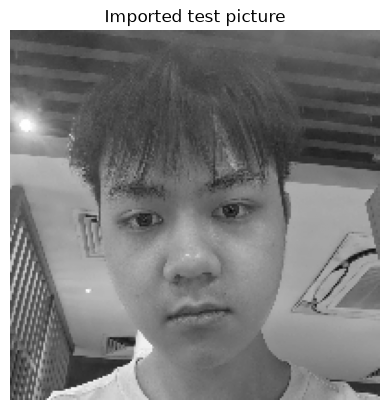

/home/sisi/projects/age-estimation/.venv/lib/python3.13/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_380']
Received: inputs=Tensor(shape=(1, 200, 200, 1))
  warnings.warn(msg)


conv2d_8: (200, 200, 32)


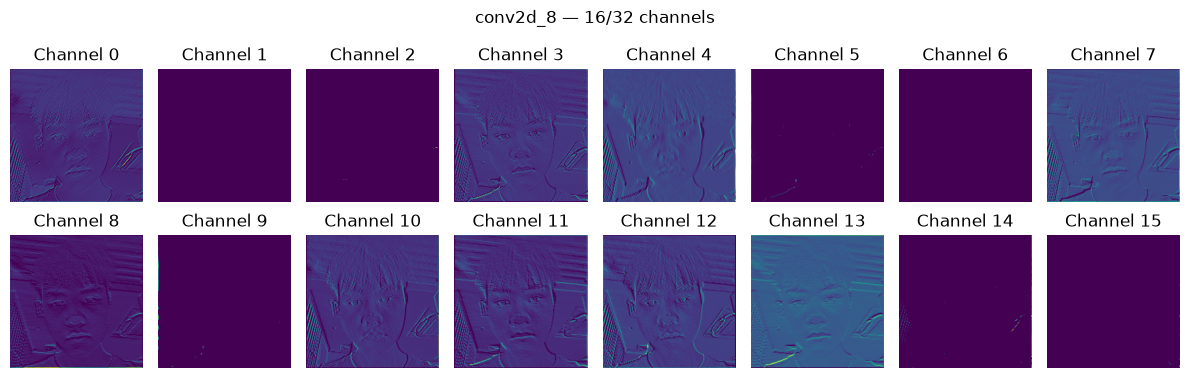

max_pooling2d_8: (100, 100, 32)


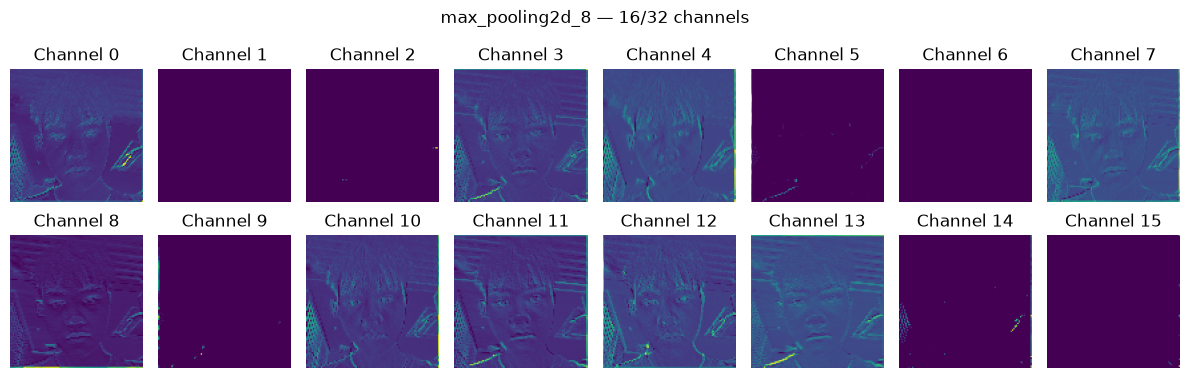

conv2d_9: (100, 100, 64)


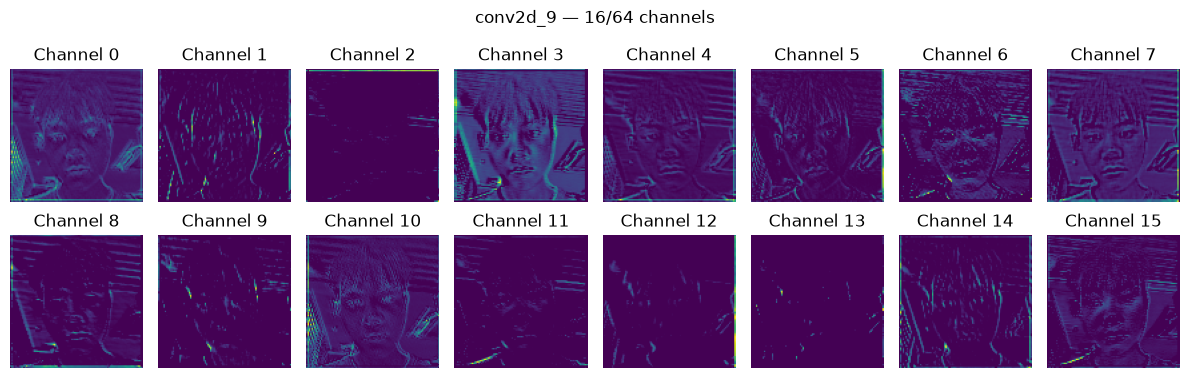

max_pooling2d_9: (50, 50, 64)


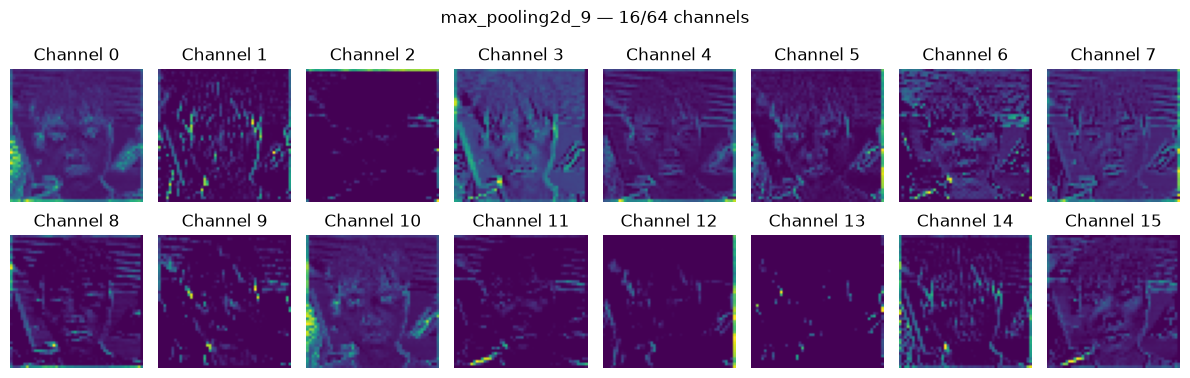

conv2d_10: (50, 50, 128)


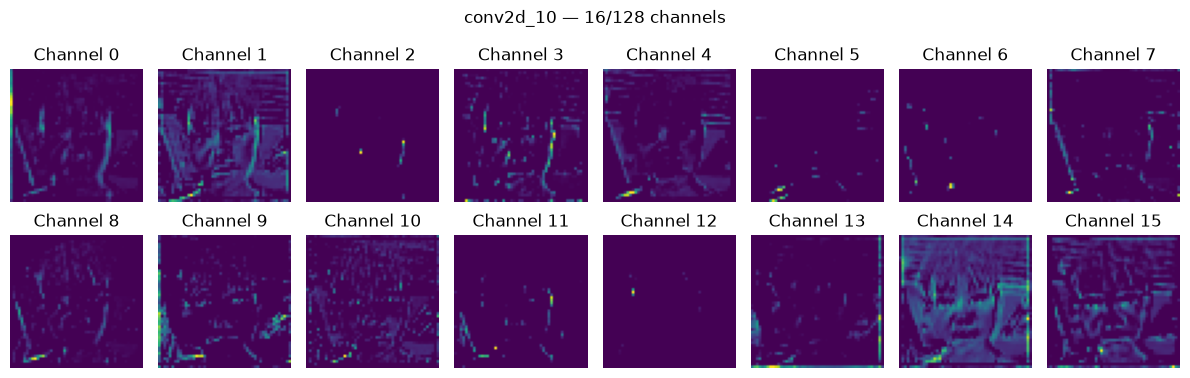

max_pooling2d_10: (25, 25, 128)


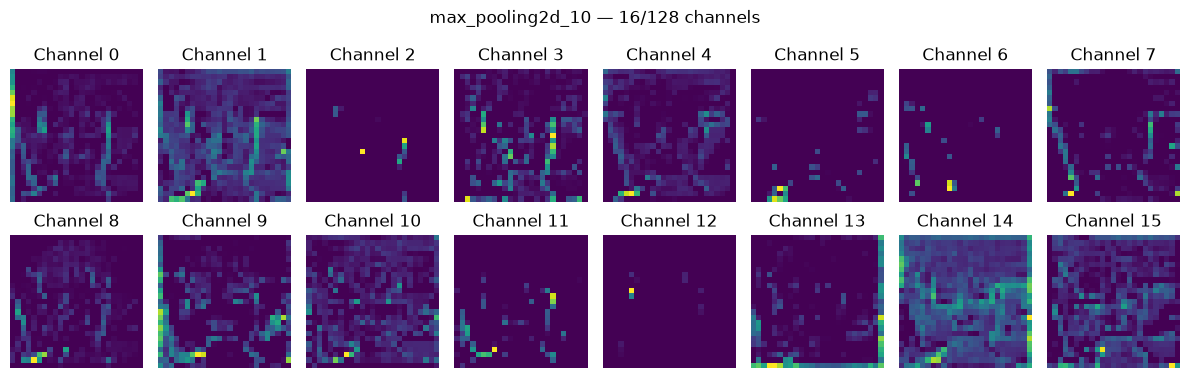

conv2d_11: (25, 25, 256)


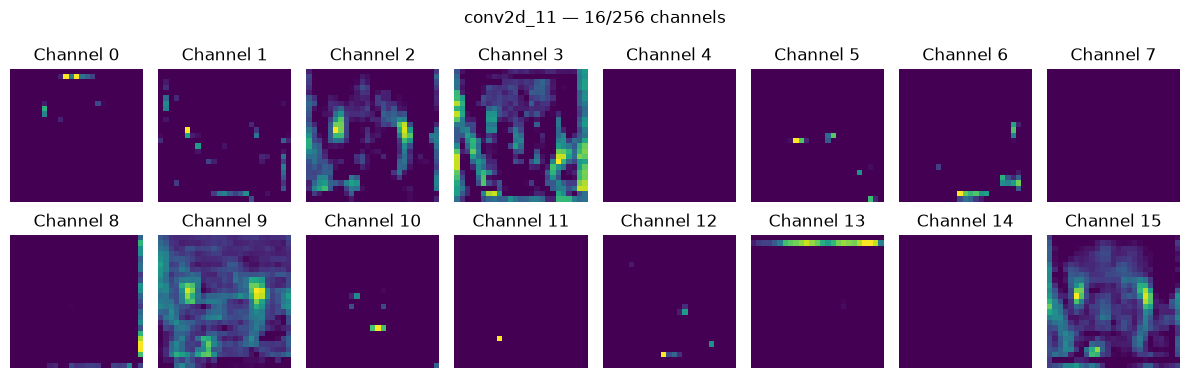

max_pooling2d_11: (12, 12, 256)


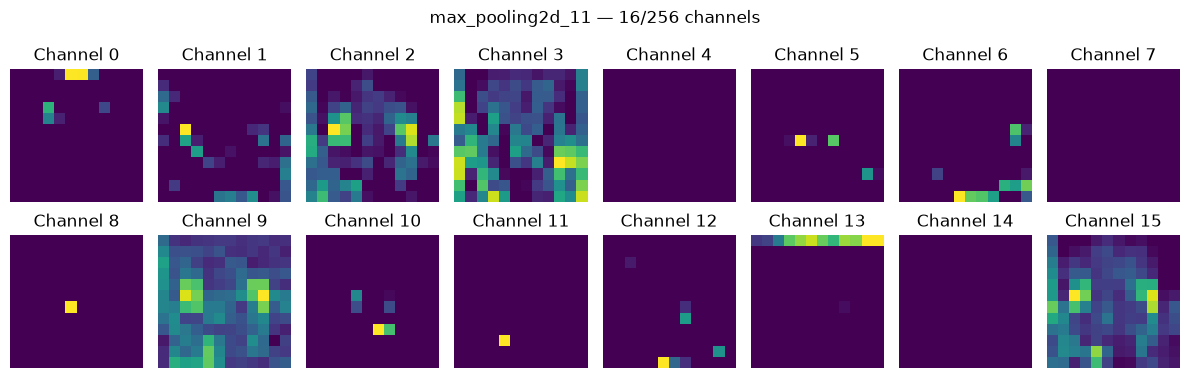

global_average_pooling2d_2: (256,)


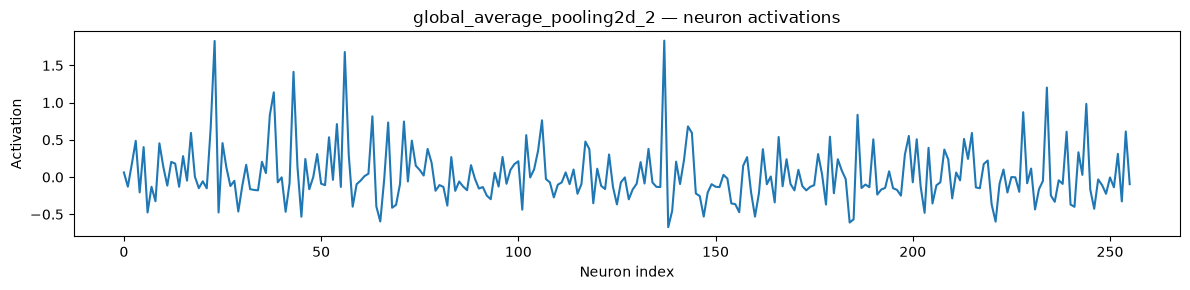

dense_6: (128,)


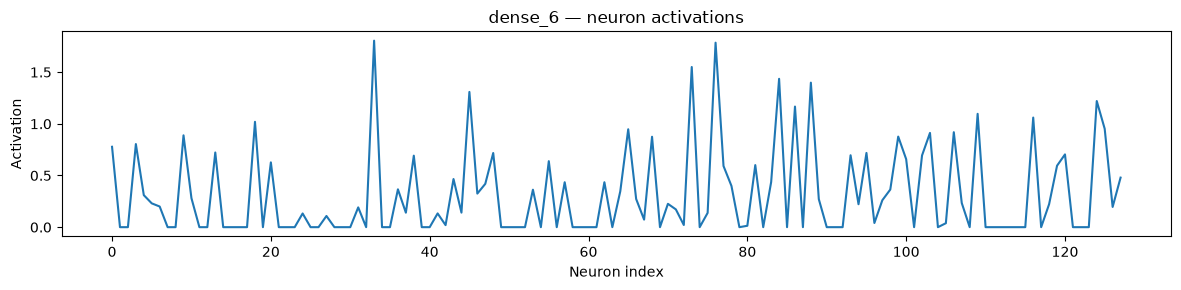

dense_7: (32,)


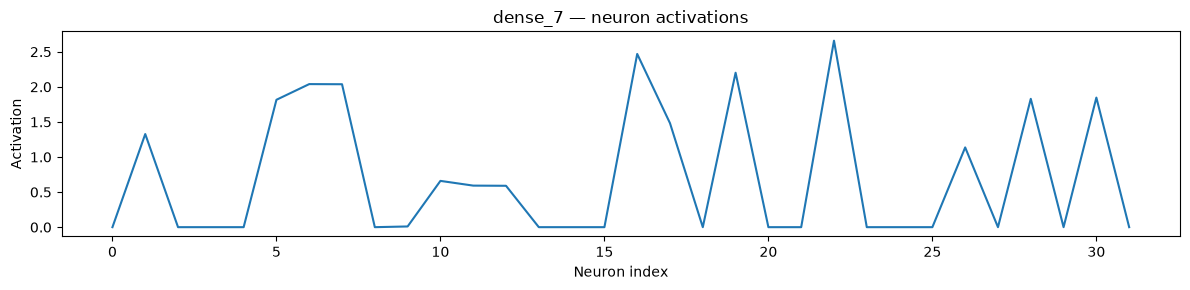

dense_8: (8,)


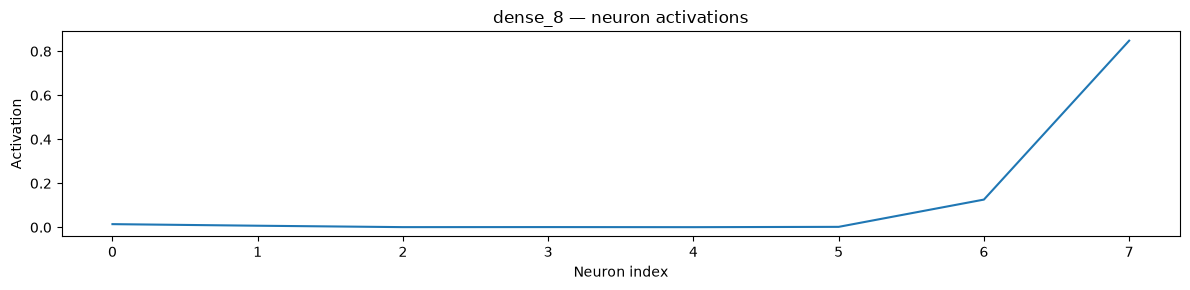

In [ ]:
# Visualize layer activations for the imported test picture
test_pic_path = Path('/home/sisi/projects/age-estimation/data/external/test_pic_cropped.jpg')
test_pic = cv2.imread(str(test_pic_path), cv2.IMREAD_COLOR)
if test_pic is None:
    raise FileNotFoundError(f'Could not read the test image at {test_pic_path}')

test_pic = cv2.cvtColor(test_pic, cv2.COLOR_BGR2GRAY)
test_pic = cv2.resize(test_pic, (200, 200))
test_pic = test_pic.astype('float32') / 255.0
test_pic = np.expand_dims(test_pic, axis=-1)

visualization_layers = [
    layer for layer in simple_model.layers
    if isinstance(layer, (Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense))
]
visualization_model = tf.keras.Model(
    inputs=simple_model.inputs,
    outputs=[layer.output for layer in visualization_layers],
)

plt.imshow(test_pic[:, :, 0], cmap='gray')
plt.title('Imported test picture')
plt.axis('off')
plt.show()

visualize_layer_outputs(visualization_model, test_pic)
